In [8]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 

using Pandas

In [15]:
df=pd.read_csv('C:/Users/Houria/Downloads/pakistan_ecommerce_sales.csv')
df

,OrderID,OrderDate,Category,Product,Region,City,UnitPrice,Quantity,DiscountPct,GrossSales,...,NetSales,CostPrice,Profit,PaymentMethod,CustomerSegment,Gender,Age,Rating,DeliveryDays,Returned
0,ORD10807,2024-09-24,Electronics,Smartphone Case,Punjab,Lahore,8064.42,1,5,8064.42,...,7661.20,5089.32,2571.88,Cash on Delivery,New,Male,21,5.0,5.0,No
1,ORD10876,2024-06-11,Grocery,Spice Set,Punjab,Rawalpindi,8099.36,1,15,8099.36,...,6884.46,4890.40,1994.06,Cash on Delivery,New,Female,34,4.0,5.0,No
2,ORD10207,2024-06-05,Beauty,Hair Oil,Punjab,Lahore,14266.52,3,15,42799.56,...,36379.63,9891.83,6704.14,Debit Card,New,Male,49,5.0,2.0,No
3,ORD11507,2023-12-24,Sports,Dumbbells,Islamabad,Islamabad,4705.63,1,15,4705.63,...,3999.79,3003.32,996.47,JazzCash,New,Male,57,2.0,6.0,No
4,ORD11521,2024-08-11,Clothing,Jacket,Islamabad,Islamabad,2813.57,1,5,2813.57,...,2672.89,2230.23,442.66,JazzCash,VIP,Female,56,5.0,7.0,No
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2005,ORD11604,2023-05-09,Home & Kitchen,LED Bulb,Punjab,Faisalabad,12902.65,4,10,51610.60,...,46449.54,9510.40,8407.94,Cash on Delivery,New,Female,28,4.0,3.0,No
2006,ORD10503,2024-05-12,Electronics,Wireless Earbuds,Balochistan,Quetta,12127.43,1,0,12127.43,...,12127.43,8667.42,3460.01,Credit Card,VIP,Female,60,5.0,2.0,No
2007,ORD10538,2023-12-22,Grocery,Dry Fruits Pack,Sindh,Karachi,14817.68,1,0,14817.68,...,14817.68,9734.38,5083.30,Cash on Delivery,New,Male,55,5.0,6.0,No
2008,ORD11221,2023-11-21,Electronics,Wireless Earbuds,Islamabad,Islamabad,8372.62,5,0,41863.10,...,41863.10,5738.81,13169.05,JazzCash,Regular,Female,23,2.0,6.0,No


In [17]:
df.shape

(2010, 21)

In [18]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2010 entries, 0 to 2009
Data columns (total 21 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   OrderID          2010 non-null   str    
 1   OrderDate        2010 non-null   str    
 2   Category         2010 non-null   str    
 3   Product          2010 non-null   str    
 4   Region           2010 non-null   str    
 5   City             2010 non-null   str    
 6   UnitPrice        2010 non-null   float64
 7   Quantity         2010 non-null   int64  
 8   DiscountPct      2010 non-null   int64  
 9   GrossSales       2010 non-null   float64
 10  DiscountAmt      2010 non-null   float64
 11  NetSales         2010 non-null   float64
 12  CostPrice        2010 non-null   float64
 13  Profit           2010 non-null   float64
 14  PaymentMethod    2010 non-null   str    
 15  CustomerSegment  2010 non-null   str    
 16  Gender           2010 non-null   str    
 17  Age              2010 non

In [22]:
print(df.dtypes)

OrderID                str
OrderDate              str
Category               str
Product                str
Region                 str
City                   str
UnitPrice          float64
Quantity             int64
DiscountPct          int64
GrossSales         float64
DiscountAmt        float64
NetSales           float64
CostPrice          float64
Profit             float64
PaymentMethod          str
CustomerSegment        str
Gender                 str
Age                  int64
Rating             float64
DeliveryDays       float64
Returned               str
dtype: object


In [24]:
df['OrderDate']=pd.to_datetime(df['OrderDate'],format='mixed')

In [27]:
df['OrderDate'].dtype

dtype('<M8[us]')

In [32]:
df['Year']=df['OrderDate'].dt.year

In [33]:
df['MonthName']=df['OrderDate'].dt.strftime('%b')

In [48]:
df.drop_duplicates(subset=['OrderID'],inplace=True)

In [52]:
df.isnull().sum()

OrderID             0
OrderDate           0
Category            0
Product             0
Region              0
City                0
UnitPrice           0
Quantity            0
DiscountPct         0
GrossSales          0
DiscountAmt         0
NetSales            0
CostPrice           0
Profit              0
PaymentMethod       0
CustomerSegment     0
Gender              0
Age                 0
Rating             40
DeliveryDays       25
Returned            0
Year                0
MonthName           0
dtype: int64

In [54]:
df['Rating']=df['Rating'].fillna(df['Rating'].median())
df['DeliveryDays']=df['DeliveryDays'].fillna(df['DeliveryDays'].median())

In [56]:
df.isnull().sum()

OrderID            0
OrderDate          0
Category           0
Product            0
Region             0
City               0
UnitPrice          0
Quantity           0
DiscountPct        0
GrossSales         0
DiscountAmt        0
NetSales           0
CostPrice          0
Profit             0
PaymentMethod      0
CustomerSegment    0
Gender             0
Age                0
Rating             0
DeliveryDays       0
Returned           0
Year               0
MonthName          0
dtype: int64

#3

In [65]:
total_revenue=df.groupby('Category')['NetSales'].sum()
total_revenue

Category
Beauty            3671499.69
Books             3030290.81
Clothing          3702296.35
Electronics       3375564.83
Grocery           3295520.57
Home & Kitchen    3623943.84
Sports            3510638.84
Toys              3981960.81
Name: NetSales, dtype: float64

In [71]:
top_5_product=df.groupby('Product')['Quantity'].sum().sort_values(ascending=False).head(5)
top_5_product

Product
Action Figure    126
LED Bulb         110
Blender          108
Soft Toy         106
Cap              105
Name: Quantity, dtype: int64

Using Numpy

In [76]:
np.array(df['NetSales'])

array([ 7661.2 ,  6884.46, 36379.63, ..., 14817.68, 41863.1 ,  7621.57],
      shape=(2000,))

In [81]:
sales_mean=np.mean(np.array(df['NetSales']))
sales_median=np.median(np.array(df['NetSales']))
sales_std=np.std(np.array(df['NetSales']))

print(sales_mean)
print(sales_median)
print(sales_std)

14095.857870000002
10427.279999999999
12561.008410387889


In [85]:
df['SalesValueSegment']=np.where(df['NetSales']>5000, 'High Value','Low Value')

In [84]:
print(df['SalesValueSegment'].value_counts())

SalesValueSegment
High Value    1509
Low Value      491
Name: count, dtype: int64


In [88]:
p25,p50,p75=np.percentile(df['Profit'].values,(25,50,75))

In [91]:
print(f'25th percentile of: {p25:.2f}')
print(f'50th percentile of: {p50:.2f}')
print(f'75th percentile of: {p75:.2f}')

25th percentile of: 1048.38
50th percentile of: 2525.38
75th percentile of: 5035.66


In [94]:
correlation_matrix=np.corrcoef(df['DiscountPct'].values,df['Quantity'].values)
correlation_value=correlation_matrix[0,1]
print('Correlation_Matrix')
print(correlation_matrix)
print(f'\ncorrelation_value :{correlation_value}')

Correlation_Matrix
[[1.         0.02146221]
 [0.02146221 1.        ]]

correlation_value :0.02146221154882001


Using Matplotlib

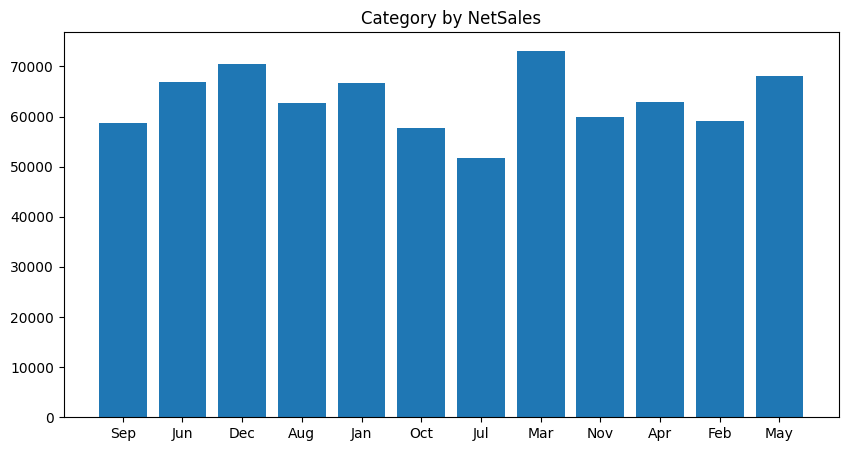

In [108]:
plt.figure(figsize=(,5))
plt.bar(data=df,x='Category',height='NetSales')
plt.title('Category by NetSales')
plt.show()

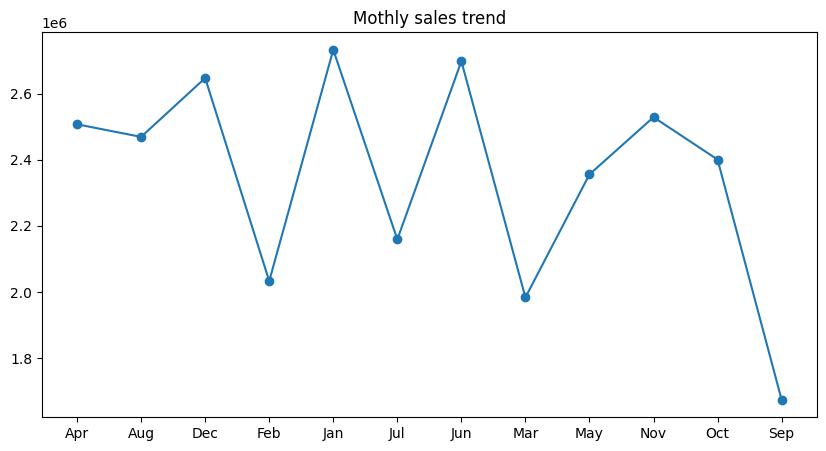

In [113]:
monthly_sales=df.groupby('MonthName')['NetSales'].sum()
plt.figure(figsize=(10,5))
plt.plot(monthly_sales.index,monthly_sales.values,marker='o')
plt.title('Mothly sales trend')
plt.show()

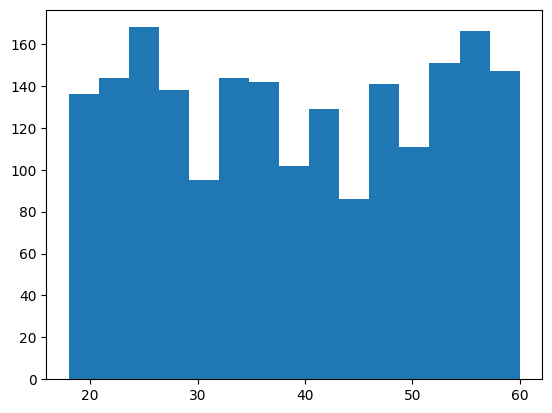

In [126]:
plt.hist(df['Age'],bins=15)
plt.show()

Using Seaborn

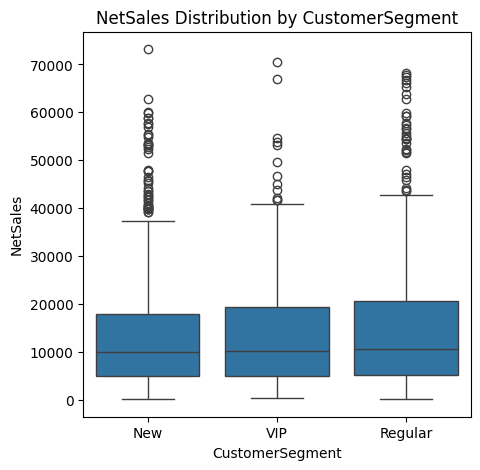

In [128]:
plt.figure(figsize=(5,5))
sns.boxplot(y='NetSales',x='CustomerSegment',data=df,gap=2, whis=1.5)
plt.title('NetSales Distribution by CustomerSegment')
plt.show()

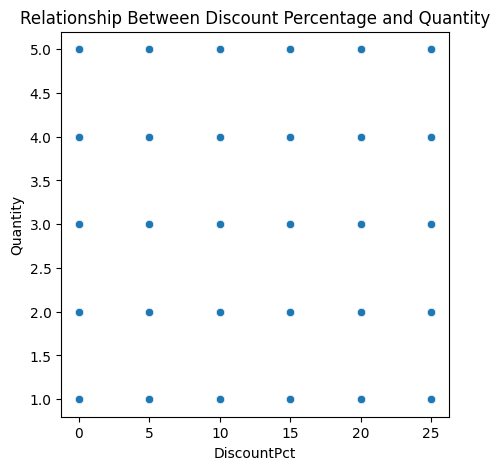

In [129]:
plt.figure(figsize=(5,5))
sns.scatterplot(y='Quantity',x='DiscountPct',data=df)
plt.title('Relationship Between Discount Percentage and Quantity')
plt.show()

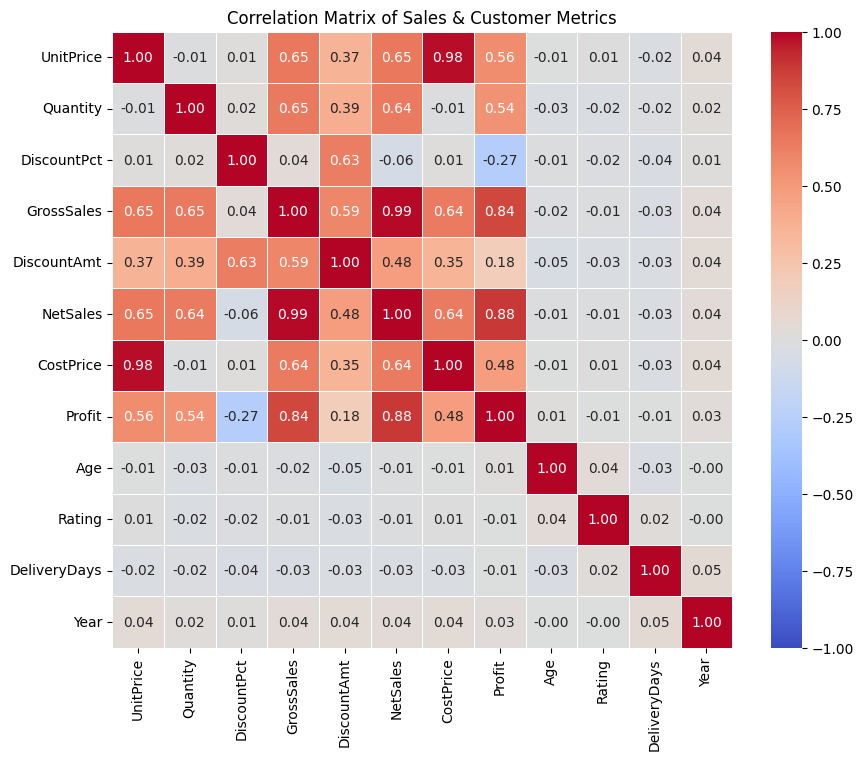

In [131]:
numeric_df = df.select_dtypes(include=['number'])
corr_matrix = numeric_df.corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr_matrix, 
    annot=True,          
    fmt=".2f",   
    cmap="coolwarm",     
    vmin=-1, vmax=1,    
    linewidths=0.5       
)
plt.title('Correlation Matrix of Sales & Customer Metrics')
plt.show()
